# **CPU Scheduling Simulator**
**Institute of Space Technology | Department of Computing | Operating Systems Lab**

**Group Members:**
**Qamar u Zaman (1015)** &  **Muhammad Zunair (1025)**
#### **Batch:** AI-01

| Task | What it does |
|---|---|
| 1 | Imports |
| 2 | Input: sample dataset / CSV upload / keyboard |
| 3 | Helper functions (metrics, CPU utilization, Gantt chart) |
| 4-9 | The 6 algorithms: FCFS, SJF, SRTF, Priority (NP + P), Round Robin |
| 10 | Run one algorithm and see full results |
| 11 | Comparison mode (all algorithms, one summary table) |
| 12 | Test cases with expected vs actual output |
| 13 |  Multilevel Feedback Queue + comparison graph |



## **Task 1: Imports**

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Done")

Done


## **Input**
Each process has: **PID, Arrival time, Burst time, Priority**.


###  **Sample dataset**
This set has equal arrival times and ties in burst/priority so the edge cases get tested.

In [15]:
sample_data = [
    # PID,  Arrival, Burst, Priority
    ["P1",  0,       8,     2],
    ["P2",  1,       4,     4],
    ["P3",  2,       9,     1],
    ["P4",  2,       5,     3],
    ["P5",  3,       2,     2],
    ["P6",  32,      3,     2],
]

df = pd.DataFrame(sample_data, columns=["PID", "Arrival", "Burst", "Priority"])

df.to_csv("processes.csv", index=False)

print("Sample dataset loaded.")
display(df)

Sample dataset loaded.


,PID,Arrival,Burst,Priority
0,P1,0,8,2
1,P2,1,4,4
2,P3,2,9,1
3,P4,2,5,3
4,P5,3,2,2
5,P6,32,3,2


## Helper functions
Every algorithm returns a **Gantt list**: a list of `(pid, start, end)` blocks, where `pid` can also be `"IDLE"`.
All metrics are calculated from that list, so we write the metric code only once.

- **Completion time** = when the process finishes
- **Turnaround time** = completion - arrival
- **Waiting time** = turnaround - burst
- **Response time** = first time it got the CPU - arrival
- **CPU utilization** = busy time / total time x 100

In [17]:
def add_block(gantt, pid, start, end):
    # Add a block to the Gantt list. Join it with the last block if it is the same process.
    if gantt and gantt[-1][0] == pid and gantt[-1][2] == start:
        gantt[-1] = (pid, gantt[-1][1], end)
    else:
        gantt.append((pid, start, end))


def calculate_metrics(df, gantt):
    # Make the per-process table: completion, turnaround, waiting, response
    rows = []
    for _, p in df.iterrows():
        blocks = [b for b in gantt if b[0] == p["PID"]]
        first_start = blocks[0][1]
        completion  = blocks[-1][2]
        turnaround  = completion - p["Arrival"]
        waiting     = turnaround - p["Burst"]
        response    = first_start - p["Arrival"]
        rows.append([p["PID"], p["Arrival"], p["Burst"], p["Priority"],
                     completion, turnaround, waiting, response])
    cols = ["PID", "Arrival", "Burst", "Priority",
            "Completion", "Turnaround", "Waiting", "Response"]
    return pd.DataFrame(rows, columns=cols)


def cpu_utilization(gantt):
    total_time = gantt[-1][2]
    busy_time = sum(end - start for pid, start, end in gantt if pid != "IDLE")
    return busy_time / total_time * 100

### Text-based Gantt chart and graphical (matplotlib) Gantt chart

In [18]:
def print_gantt(gantt):
    # Text Gantt chart, e.g.  | P1 | P2 | IDLE | P3 |
    bar = "|"
    times = ""
    for pid, start, end in gantt:
        cell = " " + pid + " "
        bar += cell + "|"
        times += str(start).ljust(len(cell) + 1)
    times += str(gantt[-1][2])
    print(bar)
    print(times)


def plot_gantt(gantt, title="Gantt Chart"):
    # Graphical Gantt chart
    pids = sorted(set(pid for pid, s, e in gantt if pid != "IDLE"))
    colors = plt.cm.tab20.colors
    color_of = {pid: colors[i % 20] for i, pid in enumerate(pids)}
    color_of["IDLE"] = "lightgrey"

    fig, ax = plt.subplots(figsize=(11, 1.8))
    for pid, start, end in gantt:
        ax.barh(0, end - start, left=start, color=color_of[pid], edgecolor="black")
        ax.text((start + end) / 2, 0, pid, ha="center", va="center", fontsize=9)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.set_title(title)
    ax.set_xticks(sorted(set([s for p, s, e in gantt] + [gantt[-1][2]])))
    plt.tight_layout()
    plt.show()

### Show the full result of one algorithm

In [19]:
def show_result(name, df, gantt, graphical=True):
    result = calculate_metrics(df, gantt)

    print("=" * 60)
    print(name)
    print("=" * 60)
    display(result)

    print("Average Completion Time :", round(result["Completion"].mean(), 2))
    print("Average Turnaround Time :", round(result["Turnaround"].mean(), 2))
    print("Average Waiting Time    :", round(result["Waiting"].mean(), 2))
    print("Average Response Time   :", round(result["Response"].mean(), 2))
    print("CPU Utilization         :", round(cpu_utilization(gantt), 2), "%")

    print("\nGantt Chart (text):")
    print_gantt(gantt)
    if graphical:
        plot_gantt(gantt, name)

## **Task 2: First Come First Serve (FCFS)**
Processes run in the order they arrive. Non-preemptive.

FCFS


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,8,8,0,0
1,P2,1,4,4,12,11,7,7
2,P3,2,9,1,21,19,10,10
3,P4,2,5,3,26,24,19,19
4,P5,3,2,2,28,25,23,23
5,P6,32,3,2,35,3,0,0


Average Completion Time : 21.67
Average Turnaround Time : 15.0
Average Waiting Time    : 9.83
Average Response Time   : 9.83
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P2 | P3 | P4 | P5 | IDLE | P6 |
0    8    12   21   26   28     32   35


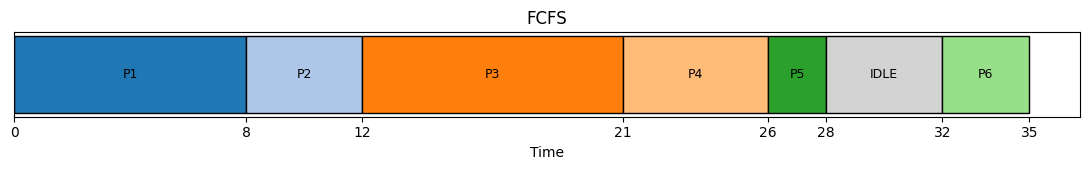

In [20]:
def fcfs(df):
    processes = df.sort_values("Arrival", kind="stable").to_dict("records")
    time = 0
    gantt = []
    for p in processes:
        if time < p["Arrival"]:
            add_block(gantt, "IDLE", time, p["Arrival"])
            time = p["Arrival"]
        add_block(gantt, p["PID"], time, time + p["Burst"])
        time += p["Burst"]
    return gantt

show_result("FCFS", df, fcfs(df))

## **Task 3: Shortest Job First (SJF), non-preemptive**
Whenever the CPU is free, pick the ready process with the **smallest burst time**.

Priority (non-preemptive) works exactly the same way, only the "choose" rule is different, so one shared function `non_preemptive()` is used for both.

SJF (Non-Preemptive)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,8,8,0,0
1,P2,1,4,4,14,13,9,9
2,P3,2,9,1,28,26,17,17
3,P4,2,5,3,19,17,12,12
4,P5,3,2,2,10,7,5,5
5,P6,32,3,2,35,3,0,0


Average Completion Time : 19.0
Average Turnaround Time : 12.33
Average Waiting Time    : 7.17
Average Response Time   : 7.17
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P5 | P2 | P4 | P3 | IDLE | P6 |
0    8    10   14   19   28     32   35


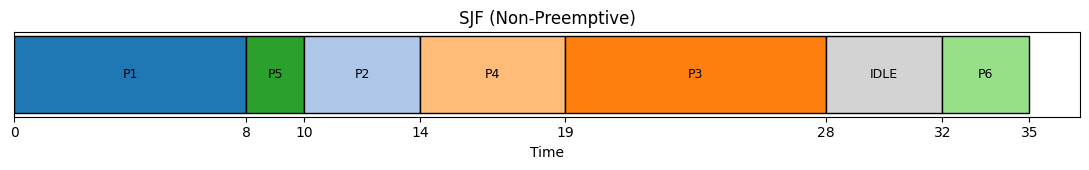

In [21]:
def non_preemptive(df, choose):
    # choose(p) gives the value to minimise, e.g. burst time or priority
    processes = df.to_dict("records")
    done = []
    time = 0
    gantt = []
    while len(done) < len(processes):
        ready = [p for p in processes if p["Arrival"] <= time and p["PID"] not in done]
        if not ready:                                # CPU idle: jump to next arrival
            next_arrival = min(p["Arrival"] for p in processes if p["PID"] not in done)
            add_block(gantt, "IDLE", time, next_arrival)
            time = next_arrival
            continue
        p = min(ready, key=lambda x: (choose(x), x["Arrival"]))   # ties -> earlier arrival
        add_block(gantt, p["PID"], time, time + p["Burst"])
        time += p["Burst"]
        done.append(p["PID"])
    return gantt


def sjf(df):
    return non_preemptive(df, lambda p: p["Burst"])

show_result("SJF (Non-Preemptive)", df, sjf(df))

## **Task 4: Shortest Remaining Time First (SRTF)**
Preemptive SJF. At every time unit, run the ready process with the **least remaining time**. A new shorter process can interrupt the running one.

Priority (preemptive) uses the same loop with a different rule, so one shared function `preemptive()` is used for both.

SRTF (Preemptive SJF)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,19,19,11,0
1,P2,1,4,4,5,4,0,0
2,P3,2,9,1,28,26,17,17
3,P4,2,5,3,12,10,5,5
4,P5,3,2,2,7,4,2,2
5,P6,32,3,2,35,3,0,0


Average Completion Time : 17.67
Average Turnaround Time : 11.0
Average Waiting Time    : 5.83
Average Response Time   : 4.0
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P2 | P5 | P4 | P1 | P3 | IDLE | P6 |
0    1    5    7    12   19   28     32   35


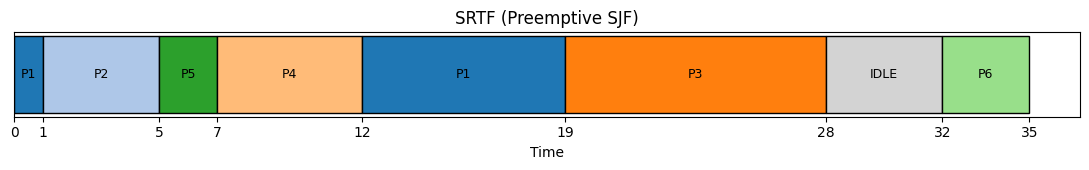

In [22]:
def preemptive(df, choose):
    # choose(p) gives the value to minimise (remaining time or priority)
    processes = df.to_dict("records")
    for p in processes:
        p["Remaining"] = p["Burst"]
    time = 0
    finished = 0
    gantt = []
    while finished < len(processes):
        ready = [p for p in processes if p["Arrival"] <= time and p["Remaining"] > 0]
        if not ready:
            add_block(gantt, "IDLE", time, time + 1)
        else:
            p = min(ready, key=lambda x: (choose(x), x["Arrival"]))
            add_block(gantt, p["PID"], time, time + 1)
            p["Remaining"] -= 1
            if p["Remaining"] == 0:
                finished += 1
        time += 1
    return gantt


def srtf(df):
    return preemptive(df, lambda p: p["Remaining"])

show_result("SRTF (Preemptive SJF)", df, srtf(df))

## **Task 5: Priority Scheduling, non-preemptive**
The ready process with the **smallest priority number** runs until it finishes.

Priority (Non-Preemptive)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,8,8,0,0
1,P2,1,4,4,28,27,23,23
2,P3,2,9,1,17,15,6,6
3,P4,2,5,3,24,22,17,17
4,P5,3,2,2,19,16,14,14
5,P6,32,3,2,35,3,0,0


Average Completion Time : 21.83
Average Turnaround Time : 15.17
Average Waiting Time    : 10.0
Average Response Time   : 10.0
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P3 | P5 | P4 | P2 | IDLE | P6 |
0    8    17   19   24   28     32   35


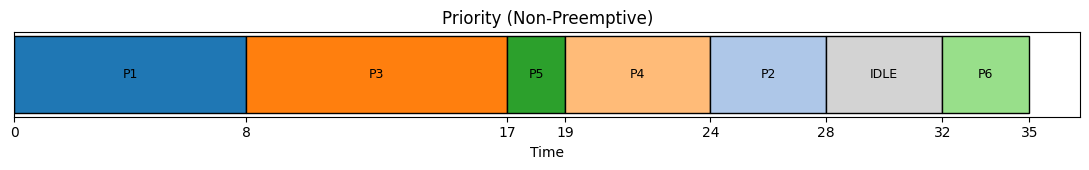

In [23]:
def priority_np(df):
    return non_preemptive(df, lambda p: p["Priority"])

show_result("Priority (Non-Preemptive)", df, priority_np(df))

## **Task 6: Priority Scheduling, preemptive**

If a higher-priority process arrives, it takes the CPU immediately.

Priority (Preemptive)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,17,17,9,0
1,P2,1,4,4,28,27,23,23
2,P3,2,9,1,11,9,0,0
3,P4,2,5,3,24,22,17,17
4,P5,3,2,2,19,16,14,14
5,P6,32,3,2,35,3,0,0


Average Completion Time : 22.33
Average Turnaround Time : 15.67
Average Waiting Time    : 10.5
Average Response Time   : 9.0
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P3 | P1 | P5 | P4 | P2 | IDLE | P6 |
0    2    11   17   19   24   28     32   35


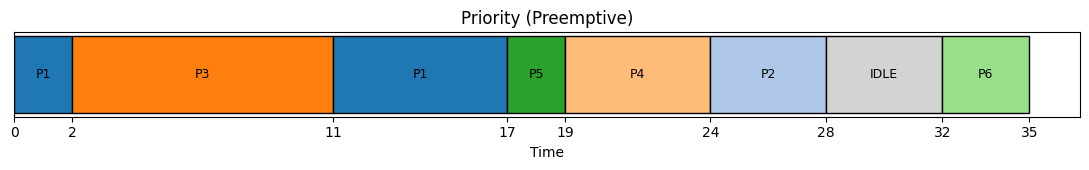

In [24]:
def priority_p(df):
    return preemptive(df, lambda p: p["Priority"])

show_result("Priority (Preemptive)", df, priority_p(df))

## **Task 7: Round Robin (user-defined time quantum)**
Each process gets the CPU for at most `quantum` time units, then goes to the back of the ready queue.

Change `QUANTUM` below to any value you want.

Round Robin (q=5)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,24,24,16,0
1,P2,1,4,4,9,8,4,4
2,P3,2,9,1,28,26,17,7
3,P4,2,5,3,19,17,12,12
4,P5,3,2,2,21,18,16,16
5,P6,32,3,2,35,3,0,0


Average Completion Time : 22.67
Average Turnaround Time : 16.0
Average Waiting Time    : 10.83
Average Response Time   : 6.5
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P2 | P3 | P4 | P5 | P1 | P3 | IDLE | P6 |
0    5    9    14   19   21   24   28     32   35


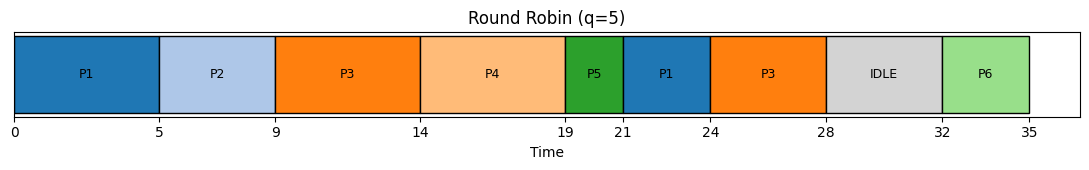

In [32]:
QUANTUM = 5

def round_robin(df, quantum):
    processes = df.sort_values("Arrival", kind="stable").to_dict("records")
    remaining = {p["PID"]: p["Burst"] for p in processes}
    queue = []
    time = 0
    i = 0                       # next process that has not yet entered the queue
    finished = 0
    gantt = []
    n = len(processes)

    while finished < n:
        while i < n and processes[i]["Arrival"] <= time:     # new arrivals join the queue
            queue.append(processes[i])
            i += 1

        if not queue:                                         # CPU idle
            add_block(gantt, "IDLE", time, processes[i]["Arrival"])
            time = processes[i]["Arrival"]
            continue

        p = queue.pop(0)
        run = min(quantum, remaining[p["PID"]])
        add_block(gantt, p["PID"], time, time + run)
        time += run
        remaining[p["PID"]] -= run

        while i < n and processes[i]["Arrival"] <= time:     # arrivals during this run
            queue.append(processes[i])
            i += 1

        if remaining[p["PID"]] > 0:
            queue.append(p)                                   # not finished -> back of queue
        else:
            finished += 1
    return gantt

show_result("Round Robin (q=" + str(QUANTUM) + ")", df, round_robin(df, QUANTUM))

## **Task 8: Choose and run any one algorithm**
Pick the algorithm from the dropdown on the right and run the cell.

SRTF


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,19,19,11,0
1,P2,1,4,4,5,4,0,0
2,P3,2,9,1,28,26,17,17
3,P4,2,5,3,12,10,5,5
4,P5,3,2,2,7,4,2,2
5,P6,32,3,2,35,3,0,0


Average Completion Time : 17.67
Average Turnaround Time : 11.0
Average Waiting Time    : 5.83
Average Response Time   : 4.0
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P2 | P5 | P4 | P1 | P3 | IDLE | P6 |
0    1    5    7    12   19   28     32   35


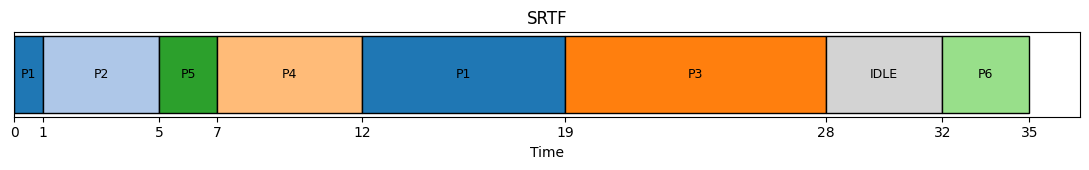

In [35]:
ALGORITHM = "SRTF"   #@param ["FCFS", "SJF", "SRTF", "Priority (Non-Preemptive)", "Priority (Preemptive)", "Round Robin"]

if ALGORITHM == "FCFS":
    g = fcfs(df)
elif ALGORITHM == "SJF":
    g = sjf(df)
elif ALGORITHM == "SRTF":
    g = srtf(df)
elif ALGORITHM == "Priority (Non-Preemptive)":
    g = priority_np(df)
elif ALGORITHM == "Priority (Preemptive)":
    g = priority_p(df)
else:
    g = round_robin(df, QUANTUM)

show_result(ALGORITHM, df, g)

## **Task9: Comparison mode**
Runs **all** algorithms on the same input and shows one summary table.

In [36]:
def get_algorithms(quantum):
    return {
        "FCFS": fcfs,
        "SJF (Non-Preemptive)": sjf,
        "SRTF (Preemptive)": srtf,
        "Priority (Non-Preemptive)": priority_np,
        "Priority (Preemptive)": priority_p,
        "Round Robin (q=" + str(quantum) + ")": lambda d: round_robin(d, quantum),
    }


def compare_all(df, quantum):
    rows = []
    for name, algo in get_algorithms(quantum).items():
        gantt = algo(df)
        result = calculate_metrics(df, gantt)
        rows.append([name,
                     round(result["Completion"].mean(), 2),
                     round(result["Turnaround"].mean(), 2),
                     round(result["Waiting"].mean(), 2),
                     round(result["Response"].mean(), 2),
                     round(cpu_utilization(gantt), 2)])
    cols = ["Algorithm", "Avg Completion", "Avg Turnaround", "Avg Waiting",
            "Avg Response", "CPU Util %"]
    return pd.DataFrame(rows, columns=cols)


summary = compare_all(df, QUANTUM)
display(summary)

best_wait = summary.loc[summary["Avg Waiting"].idxmin(), "Algorithm"]
best_turn = summary.loc[summary["Avg Turnaround"].idxmin(), "Algorithm"]
best_resp = summary.loc[summary["Avg Response"].idxmin(), "Algorithm"]
print("Best average waiting time    :", best_wait)
print("Best average turnaround time :", best_turn)
print("Best average response time   :", best_resp)

,Algorithm,Avg Completion,Avg Turnaround,Avg Waiting,Avg Response,CPU Util %
0,FCFS,21.67,15.00,9.83,9.83,88.57
1,SJF (Non-Preemptive),19.00,12.33,7.17,7.17,88.57
2,SRTF (Preemptive),17.67,11.00,5.83,4.00,88.57
3,Priority (Non-Preemptive),21.83,15.17,10.00,10.00,88.57
4,Priority (Preemptive),22.33,15.67,10.50,9.00,88.57
5,Round Robin (q=5),22.67,16.00,10.83,6.50,88.57


Best average waiting time    : SRTF (Preemptive)
Best average turnaround time : SRTF (Preemptive)
Best average response time   : SRTF (Preemptive)


### **Gantt charts of all algorithms together**

In [28]:
for name, algo in get_algorithms(QUANTUM).items():
    print(name)
    print_gantt(algo(df))
    print()

FCFS
| P1 | P2 | P3 | P4 | P5 | IDLE | P6 |
0    8    12   21   26   28     32   35

SJF (Non-Preemptive)
| P1 | P5 | P2 | P4 | P3 | IDLE | P6 |
0    8    10   14   19   28     32   35

SRTF (Preemptive)
| P1 | P2 | P5 | P4 | P1 | P3 | IDLE | P6 |
0    1    5    7    12   19   28     32   35

Priority (Non-Preemptive)
| P1 | P3 | P5 | P4 | P2 | IDLE | P6 |
0    8    17   19   24   28     32   35

Priority (Preemptive)
| P1 | P3 | P1 | P5 | P4 | P2 | IDLE | P6 |
0    2    11   17   19   24   28     32   35

Round Robin (q=3)
| P1 | P2 | P3 | P4 | P5 | P1 | P2 | P3 | P4 | P1 | P3 | IDLE | P6 |
0    3    6    9    12   14   17   18   21   23   25   28     32   35



## **Task 10: Test cases (expected vs actual)**
Expected values were calculated **by hand** (not by the code), then compared with the program output.

**Test 1: Classic textbook set.** P1(0,7), P2(2,4), P3(4,1), P4(5,4), as (arrival, burst).
| Algorithm | Expected avg waiting time |
|---|---|
| FCFS | 4.75 |
| SJF | 4.00 |
| SRTF | 3.00 |
| Round Robin q=2 | 5.00 |

**Test 2: CPU idle gap.** P1(0,2), P2(5,3), P3(6,1). FCFS: P1 runs 0-2, CPU idle 2-5, P2 runs 5-8, P3 runs 8-9.
Expected: avg waiting = 0.67, CPU utilization = 66.67% (6 busy of 9).

**Test 3: Equal arrival times + ties.** All arrive at 0. P1(burst 4, prio 2), P2(4, 2), P3(2, 1), P4(4, 3).
Expected: Priority NP order is P3, P1, P2, P4 and avg waiting = 4.5. FCFS avg waiting = 5.5.

In [29]:
def make_df(rows):
    return pd.DataFrame(rows, columns=["PID", "Arrival", "Burst", "Priority"])

def avg_wait(d, gantt):
    return round(calculate_metrics(d, gantt)["Waiting"].mean(), 2)

def order_of(gantt):
    return [pid for pid, s, e in gantt]

test_results = []

def check(test, what, expected, actual):
    status = "PASS" if expected == actual else "FAIL"
    test_results.append([test, what, expected, actual, status])

# ---- Test 1
t1 = make_df([["P1", 0, 7, 1], ["P2", 2, 4, 1], ["P3", 4, 1, 1], ["P4", 5, 4, 1]])
check("Test 1", "FCFS avg waiting", 4.75, avg_wait(t1, fcfs(t1)))
check("Test 1", "SJF avg waiting",  4.00, avg_wait(t1, sjf(t1)))
check("Test 1", "SRTF avg waiting", 3.00, avg_wait(t1, srtf(t1)))
check("Test 1", "RR (q=2) avg waiting", 5.00, avg_wait(t1, round_robin(t1, 2)))

# ---- Test 2
t2 = make_df([["P1", 0, 2, 1], ["P2", 5, 3, 1], ["P3", 6, 1, 1]])
g2 = fcfs(t2)
check("Test 2", "FCFS avg waiting", 0.67, avg_wait(t2, g2))
check("Test 2", "CPU utilization %", 66.67, round(cpu_utilization(g2), 2))
check("Test 2", "Gantt order", ["P1", "IDLE", "P2", "P3"], order_of(g2))

# ---- Test 3
t3 = make_df([["P1", 0, 4, 2], ["P2", 0, 4, 2], ["P3", 0, 2, 1], ["P4", 0, 4, 3]])
g3 = priority_np(t3)
check("Test 3", "Priority NP order", ["P3", "P1", "P2", "P4"], order_of(g3))
check("Test 3", "Priority NP avg waiting", 4.5, avg_wait(t3, g3))
check("Test 3", "FCFS avg waiting", 5.5, avg_wait(t3, fcfs(t3)))

test_table = pd.DataFrame(test_results, columns=["Test", "Check", "Expected", "Actual", "Result"])
display(test_table)
print(test_table["Result"].value_counts().to_string())

,Test,Check,Expected,Actual,Result
0,Test 1,FCFS avg waiting,4.75,4.75,PASS
1,Test 1,SJF avg waiting,4.0,4.0,PASS
2,Test 1,SRTF avg waiting,3.0,3.0,PASS
3,Test 1,RR (q=2) avg waiting,5.0,5.0,PASS
4,Test 2,FCFS avg waiting,0.67,0.67,PASS
5,Test 2,CPU utilization %,66.67,66.67,PASS
6,Test 2,Gantt order,"[P1, IDLE, P2, P3]","[P1, IDLE, P2, P3]",PASS
7,Test 3,Priority NP order,"[P3, P1, P2, P4]","[P3, P1, P2, P4]",PASS
8,Test 3,Priority NP avg waiting,4.5,4.5,PASS
9,Test 3,FCFS avg waiting,5.5,5.5,PASS


Result
PASS    10


##  **Multilevel Feedback Queue (MLFQ)**
3 queues with time quantum 2, 4 and 8. Every new process enters the top queue. If it uses its whole quantum without finishing, it moves down one queue. The CPU always serves the highest non-empty queue.

Multilevel Feedback Queue (2, 4, 8)


,PID,Arrival,Burst,Priority,Completion,Turnaround,Waiting,Response
0,P1,0,8,2,25,25,17,0
1,P2,1,4,4,16,15,11,1
2,P3,2,9,1,28,26,17,2
3,P4,2,5,3,23,21,16,4
4,P5,3,2,2,10,7,5,5
5,P6,32,3,2,35,3,0,0


Average Completion Time : 22.83
Average Turnaround Time : 16.17
Average Waiting Time    : 11.0
Average Response Time   : 2.0
CPU Utilization         : 88.57 %

Gantt Chart (text):
| P1 | P2 | P3 | P4 | P5 | P1 | P2 | P3 | P4 | P1 | P3 | IDLE | P6 |
0    2    4    6    8    10   14   16   20   23   25   28     32   35


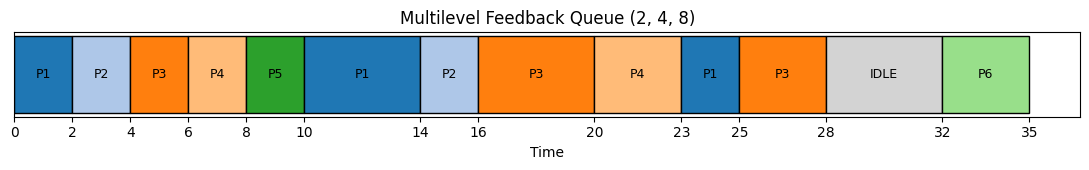

In [30]:
def mlfq(df, quanta=(2, 4, 8)):
    processes = df.sort_values("Arrival", kind="stable").to_dict("records")
    remaining = {p["PID"]: p["Burst"] for p in processes}
    queues = [[] for _ in quanta]
    time = 0
    i = 0
    finished = 0
    gantt = []
    n = len(processes)

    while finished < n:
        while i < n and processes[i]["Arrival"] <= time:
            queues[0].append((processes[i], 0))      # new process -> top queue
            i += 1

        level = None
        for lv in range(len(queues)):                # highest non-empty queue
            if queues[lv]:
                level = lv
                break

        if level is None:                            # CPU idle
            add_block(gantt, "IDLE", time, processes[i]["Arrival"])
            time = processes[i]["Arrival"]
            continue

        p, lv = queues[level].pop(0)
        run = min(quanta[lv], remaining[p["PID"]])
        add_block(gantt, p["PID"], time, time + run)
        time += run
        remaining[p["PID"]] -= run

        while i < n and processes[i]["Arrival"] <= time:
            queues[0].append((processes[i], 0))
            i += 1

        if remaining[p["PID"]] > 0:
            new_level = min(lv + 1, len(queues) - 1)  # move one queue down
            queues[new_level].append((p, new_level))
        else:
            finished += 1
    return gantt

show_result("Multilevel Feedback Queue (2, 4, 8)", df, mlfq(df))

###  **Comparison graph of average waiting time (with MLFQ added)**

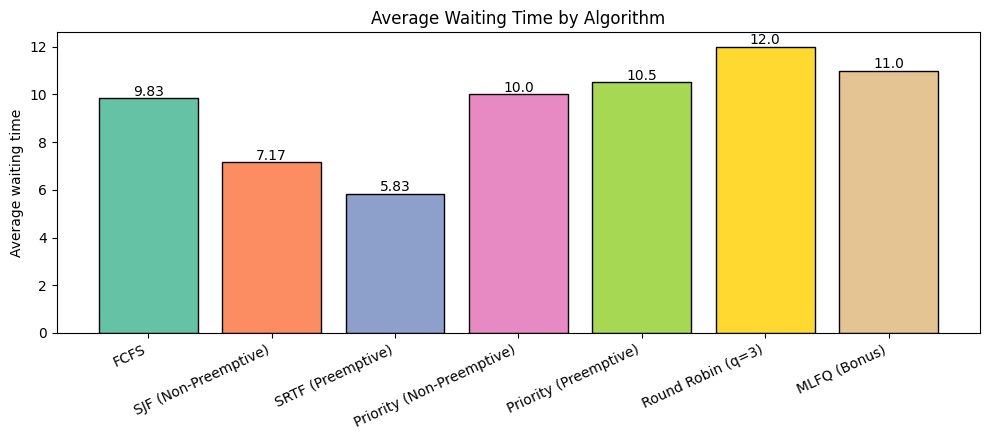

In [31]:
all_algorithms = get_algorithms(QUANTUM)
all_algorithms["MLFQ (Bonus)"] = mlfq

names = []
waits = []
for name, algo in all_algorithms.items():
    names.append(name)
    waits.append(calculate_metrics(df, algo(df))["Waiting"].mean())

plt.figure(figsize=(10, 4.5))
bars = plt.bar(names, waits, color=plt.cm.Set2.colors[:len(names)], edgecolor="black")
for bar, w in zip(bars, waits):
    plt.text(bar.get_x() + bar.get_width() / 2, w + 0.1, round(w, 2), ha="center")
plt.ylabel("Average waiting time")
plt.title("Average Waiting Time by Algorithm")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()